Section 1: Constants

In [15]:
"""
Biophysical constants for the Hodgkin-Huxley squid giant axon model.

Values are the original empirical fits from Hodgkin & Huxley (1952),
"A quantitative description of membrane current and its application to
conduction and excitation in nerve". Page #520.

To get the values accepted today, the voltage scale has to be shifted by -65 mV.
https://lcnwww.epfl.ch/gerstner/SPNM/node14.html#table-HH1
"""

C_m = 1.0      # membrane capacitance, uF/cm^2
g_Na = 120.0   # max sodium conductance, mS/cm^2
g_K = 36.0     # max potassium conductance, mS/cm^2
g_L = 0.3      # max leak conductance, mS/cm^2
E_Na = 50.0    # sodium reversal (equilibrium) potential, mV
E_K = -77.0    # potassium reversal potential, mV
E_L = -54.387  # leak reversal potential, mV


Section 2: Gating Kinetics

In [16]:
"""
Voltage-dependent gating kinetics for the m (Na activation), h (Na
inactivation), and n (K activation) gates.

Each gate x relaxes according to:
    dx/dt = alpha_x(V) * (1 - x) - beta_x(V) * x

alpha_x is the voltage-dependent opening rate, beta_x the closing rate.
Formulas are the standard modern-convention versions (V = actual membrane
potential in mV) of Hodgkin & Huxley's original empirical fits.

In their original 1952 paper, Hodgkin and Huxley used an older convention where:
The resting membrane potential was set to exactly 0 mV.The sign of the voltage 
was inverted compared to today (depolarization was treated as a negative displacement).
Modern neuroscience sets the outside of the cell to 0 mV, meaning a typical 
neuron's resting potential sits at -65 mV. To convert from the original paper's voltage
V_orig to modern voltage V_mod, the formula is: V_orig = -(V_mod+65).
"""

import numpy as np

def alpha_m(V):
    return 0.1 * (V + 40.0) / (1.0 - np.exp(-(V + 40.0) / 10.0))


def beta_m(V):
    return 4.0 * np.exp(-(V + 65.0) / 18.0)


def alpha_h(V):
    return 0.07 * np.exp(-(V + 65.0) / 20.0)


def beta_h(V):
    return 1.0 / (np.exp(-(V + 35.0) / 10.0) + 1.0)


def alpha_n(V):
    return 0.01 * (V + 55.0) / (1.0 - np.exp(-(V + 55.0) / 10.0))


def beta_n(V):
    return 0.125 * np.exp(-(V + 65.0) / 80.0)


def steady_state(V):
    """Return (m_inf, h_inf, n_inf) at a given voltage — useful for
    initializing simulations at rest, or for building activation curves."""
    m_inf = alpha_m(V) / (alpha_m(V) + beta_m(V))
    h_inf = alpha_h(V) / (alpha_h(V) + beta_h(V))
    n_inf = alpha_n(V) / (alpha_n(V) + beta_n(V))
    return m_inf, h_inf, n_inf


Section 2.1: Gating Kinetics

In [18]:
# Testing code to verify that the gating kinetics functions are working correctly

def test_steady_state_gates_in_valid_range():
    """Gating variables are probabilities — must lie in [0, 1]."""
    m_inf, h_inf, n_inf = steady_state(-65.0)
    for gate in (m_inf, h_inf, n_inf):
        assert 0.0 <= gate <= 1.0


# Test the gating kinetics functions at a specific voltage
v10 = 10

assert alpha_m(v10) == 5.033918274531521
assert beta_m(v10) == 0.062015414396037256
assert alpha_h(v10) == 0.0016462422099206377
assert beta_h(v10) == 0.9890130573694068
assert alpha_n(v10) == 0.65097870690175
assert beta_n(v10) == 0.048950703334599874
test_steady_state_gates_in_valid_range()

Section 3: HH 4 coupled ODEs

In [21]:
"""
The Hodgkin-Huxley system of 4 coupled ODEs — the vector field that every
integrator in this package operates on.
"""


def hh_derivatives(state, t, I_inj_func):
    """
    Parameters
    ----------
    state : array-like [V, m, h, n]
    t : float, current time in ms
    I_inj_func : callable, I_inj_func(t) -> injected current in uA/cm^2

    Returns
    -------
    np.ndarray, d(state)/dt
    """
    V = state[0]
    m = state[1]
    h = state[2]
    n = state[3]
    dVdt = (I_inj_func(t) - g_K * n**4 * (V - E_K) - g_Na * h * m**3 * (V - E_Na) - g_L * (V - E_L)) / C_m
    dmdt = alpha_m(V) * (1.0 - m) - beta_m(V) * m
    dhdt = alpha_h(V) * (1.0 - h) - beta_h(V) * h
    dndt = alpha_n(V) * (1.0 - n) - beta_n(V) * n

    return np.array([dVdt, dmdt, dhdt, dndt])


Section 4: ODE Integrators

In [28]:
"""
Numerical integrators for the HH ODE(Ordinary Differential Equation) system.

Kept separate from model.py deliberately: the vector field (physics) and
the integration method (numerics) are conceptually different things, and
this project's Stage 1 goal is explicitly to compare integration methods
on the same vector field.
"""


def euler_integrate(state0, t_array, I_inj_func):
    dt = t_array[1] - t_array[0]
    states = np.zeros((len(t_array), len(state0)))
    states[0] = state0
    for i in range(1, len(t_array)):
        deriv = hh_derivatives(states[i - 1], t_array[i - 1], I_inj_func)
        states[i] = states[i - 1] + dt * deriv
    return states


def rk4_integrate(state0, t_array, I_inj_func):
    dt = t_array[1] - t_array[0]

    states = np.zeros((len(t_array), len(state0)))
    states[0] = state0
    for i in range(1, len(t_array)):
        t = t_array[i - 1]
        s = states[i - 1]
        k1 = hh_derivatives(s, t, I_inj_func)
        k2 = hh_derivatives(s + dt/2 * k1, t + dt/2, I_inj_func)
        k3 = hh_derivatives(s + dt/2 * k2, t + dt/2, I_inj_func)
        k4 = hh_derivatives(s + dt * k3, t + dt, I_inj_func)
        states[i] = states[i - 1] + (dt/6) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
    return states


Section 5: Stimulus functions

In [43]:
"""
Injected-current stimulus functions, mimicking current-clamp experiments.
Each function returns a callable I_inj(t) -> current in uA/cm^2, so it can
be passed directly to hh_derivatives / the integrators.
"""


def step_current(amplitude, t_on, t_off):
    """A single rectangular current step."""
    def I_inj(t):
        return amplitude if t_on <= t <= t_off else 0.0
    return I_inj


def double_pulse_current(amplitude, t_on1, t_off1, t_on2, t_off2):
    """Two current steps — useful for probing refractory period effects."""
    def I_inj(t):
        if t_on1 <= t <= t_off1:
            return amplitude
        elif t_on2 <= t <= t_off2:
            return amplitude
        else:
            return 0.0

        
    return I_inj


def ramp_current(start_amp, end_amp, t_start, t_end):
    """A linearly ramping current between t_start and t_end."""
    def I_inj(t):
        if t <= t_start:
            return start_amp
        elif t_start <= t <= t_end:
            return (end_amp - start_amp)*(t - t_start)/(t_end - t_start) + start_amp
        else:
            return end_amp
        
    return I_inj


Section 5.1: Tests

In [30]:
# Testing code to verify that the integrators and stimulus functions are working correctly

def test_resting_potential_is_stable_without_stimulus():
    """With zero injected current, a neuron started at rest should stay
    near -65 mV (allowing small numerical drift)."""
    V0 = -65.0
    m0, h0, n0 = steady_state(V0)
    state0 = np.array([V0, m0, h0, n0])

    no_current = step_current(amplitude=0.0, t_on=0.0, t_off=0.0)
    t_array = np.arange(0.0, 20.0, 0.01)
    states = rk4_integrate(state0, t_array, no_current)
    a = np.abs(states[:, 0] - V0)
    assert np.all(np.abs(states[:, 0] - V0) < 1.0)


def test_suprathreshold_current_produces_a_spike():
    """A strong enough current step should produce a spike (V > 0 mV
    at some point), since threshold for this parameter set is well
    below 10 uA/cm^2."""
    V0 = -65.0
    m0, h0, n0 = steady_state(V0)
    state0 = np.array([V0, m0, h0, n0])

    strong_current = step_current(amplitude=10.0, t_on=5.0, t_off=30.0)
    t_array = np.arange(0.0, 50.0, 0.01)
    states = rk4_integrate(state0, t_array, strong_current)

    assert np.max(states[:, 0]) > 0.0


def test_subthreshold_current_does_not_spike():
    """A very weak current step should NOT produce a full spike."""
    V0 = -65.0
    m0, h0, n0 = steady_state(V0)
    state0 = np.array([V0, m0, h0, n0])

    weak_current = step_current(amplitude=0.5, t_on=5.0, t_off=30.0)
    t_array = np.arange(0.0, 50.0, 0.01)
    states = rk4_integrate(state0, t_array, weak_current)

    assert np.max(states[:, 0]) < 0.0

In [31]:
test_resting_potential_is_stable_without_stimulus()
test_suprathreshold_current_produces_a_spike()
test_subthreshold_current_does_not_spike()

Section 6: Plots

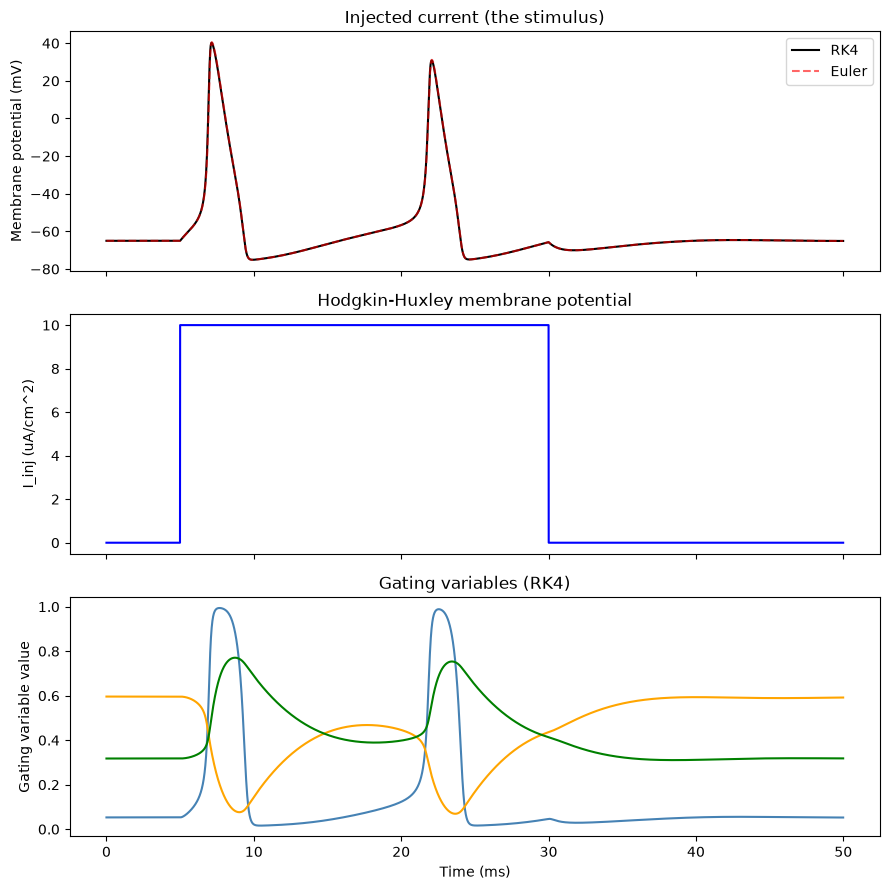

In [55]:
"""
Stage 1: Single Hodgkin-Huxley neuron, step current, RK4 vs Euler comparison.

"""

import matplotlib.pyplot as plt

# Initial conditions: resting steady state
V0 = -65.0
m0, h0, n0 = steady_state(V0)
state0 = np.array([V0, m0, h0, n0])

# Stimulus and time base
I_inj = step_current(amplitude=10.0, t_on=5.0, t_off=30.0)
dt = 0.01
t_array = np.arange(0.0, 50.0, dt)

I_injarray = np.zeros(len(t_array))
for i in range(len(t_array)):
    I_injarray[i - 1] = I_inj(t_array[i - 1])

# Integrate
states_rk4 = rk4_integrate(state0, t_array, I_inj)
states_euler = euler_integrate(state0, t_array, I_inj)

# Plot
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

axes[0].plot(t_array, states_rk4[:, 0], label='RK4', color='black')
axes[0].plot(t_array, states_euler[:, 0], label='Euler', color='red', alpha=0.6, linestyle='--')
axes[0].set_ylabel('Membrane potential (mV)')
axes[0].set_title('Injected current (the stimulus)')
axes[0].legend()

axes[1].plot(t_array, I_injarray, color='b')
axes[1].set_ylabel('I_inj (uA/cm^2)')
axes[1].set_title('Hodgkin-Huxley membrane potential')

axes[2].plot(t_array, states_rk4[:, 1], label='m (Na activation)', color='steelblue')
axes[2].plot(t_array, states_rk4[:, 2], label='h (Na inactivation)', color='orange')
axes[2].plot(t_array, states_rk4[:, 3], label='n (K activation)', color='g')
axes[2].set_ylabel('Gating variable value')
axes[2].set_xlabel('Time (ms)')
axes[2].set_title('Gating variables (RK4)')

plt.tight_layout()

plt.show()
